In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
done = pd.read_csv("../data/raw/scb_completed_dwellings_by_tenure.csv")
done.head()

,Region_code,Region,Hustyp_code,Hustyp,Upplatelseform_code,Upplatelseform,ContentsCode_code,ContentsCode,Tid_code,Tid,value
0,1,Stockholms län,FLERBO,flerbostadshus,1,hyresrätt,0000005O,Antal,1991,1991,4305
1,1,Stockholms län,FLERBO,flerbostadshus,1,hyresrätt,0000005O,Antal,1992,1992,4194
2,1,Stockholms län,FLERBO,flerbostadshus,1,hyresrätt,0000005O,Antal,1993,1993,3575
3,1,Stockholms län,FLERBO,flerbostadshus,1,hyresrätt,0000005O,Antal,1994,1994,2425
4,1,Stockholms län,FLERBO,flerbostadshus,1,hyresrätt,0000005O,Antal,1995,1995,989


In [3]:
print(done.shape)
done["Region"].unique()[:5]

(5670, 11)


<StringArray>
['Stockholms län', 'Upplands Väsby', 'Vallentuna', 'Österåker', 'Värmdö']
Length: 5, dtype: str

In [8]:
rentals = done[
    (done["Region"] == "Stockholms län")
    & (done["Hustyp"] == "flerbostadshus")
    & (done["Upplatelseform"] == "bostadsrätt")
    & (done["Tid"] >= 2010)
]
rentals = rentals[["Tid", "value"]].rename(columns={"Tid": "year", "value": "completed_rentals"})
rentals

,year,completed_rentals
54,2010,2931
55,2011,2867
56,2012,3739
57,2013,4523
58,2014,4449
59,2015,5873
60,2016,6476
61,2017,8819
62,2018,8656
63,2019,7735


In [5]:
rates = pd.read_csv("../data/raw/riksbank_interest_rates_daily.csv", parse_dates=["date"])
rates["year"] = rates["date"].dt.year

yearly_rates = (
    rates.groupby(["series_id", "year"])["value"].mean()
    .reset_index()
    .pivot(index="year", columns="series_id", values="value")
    .reset_index()
)
yearly_rates[["year", "SECBREPOEFF", "SEMB5YCACOMB"]].round(2)

series_id,year,SECBREPOEFF,SEMB5YCACOMB
0,2010,0.51,3.23
1,2011,1.76,3.65
2,2012,1.46,2.53
3,2013,0.99,2.28
4,2014,0.46,1.46
5,2015,-0.25,0.86
6,2016,-0.48,0.60
7,2017,-0.50,0.53
8,2018,-0.50,0.77
9,2019,-0.26,0.37


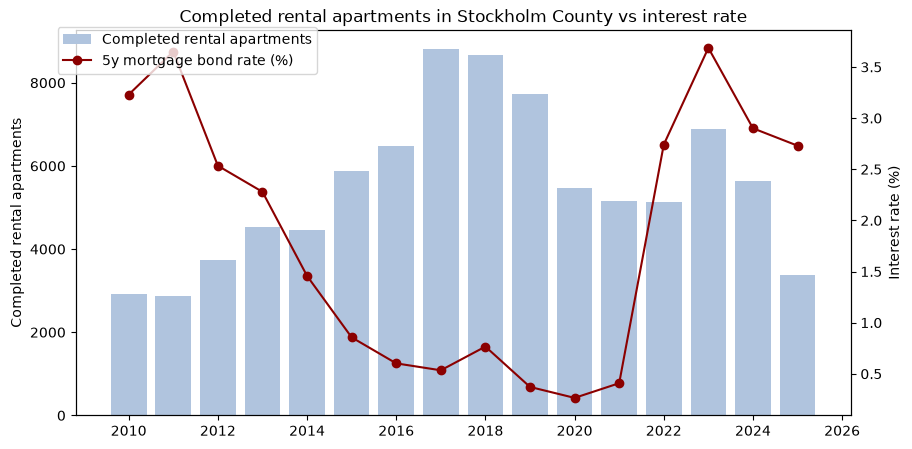

In [9]:
df = rentals.merge(yearly_rates[["year", "SEMB5YCACOMB"]], on="year")

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(df["year"], df["completed_rentals"], color="lightsteelblue", label="Completed rental apartments")
ax1.set_ylabel("Completed rental apartments")

ax2 = ax1.twinx()
ax2.plot(df["year"], df["SEMB5YCACOMB"], color="darkred", marker="o", label="5y mortgage bond rate (%)")
ax2.set_ylabel("Interest rate (%)")

plt.title("Completed rental apartments in Stockholm County vs interest rate")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
plt.show()

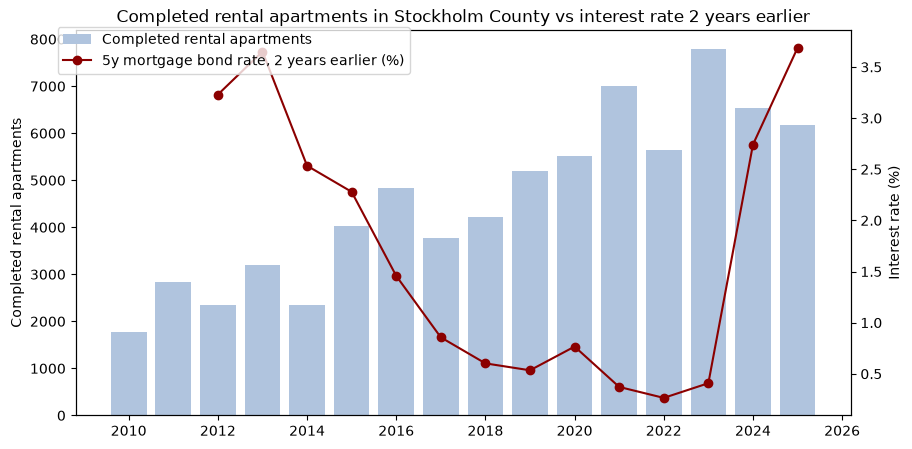

,year,completed,SEMB5YCACOMB,rate_earlier
0,2010,1774,3.23,NaN
1,2011,2831,3.65,NaN
2,2012,2337,2.53,3.23
3,2013,3204,2.28,3.65
4,2014,2345,1.46,2.53
5,2015,4034,0.86,2.28
6,2016,4844,0.60,1.46
7,2017,3765,0.53,0.86
8,2018,4224,0.77,0.60
9,2019,5191,0.37,0.53


In [10]:
# Choose what to look at: "hyresrätt" or "bostadsrätt"
tenure = "hyresrätt"
lag_years = 2  # building time: compare with the interest rate X years earlier

# 1. Filter completed dwellings
data = done[
    (done["Region"] == "Stockholms län")
    & (done["Hustyp"] == "flerbostadshus")
    & (done["Upplatelseform"] == tenure)
    & (done["Tid"] >= 2010)
][["Tid", "value"]].rename(columns={"Tid": "year", "value": "completed"})

# 2. Add the interest rate, and the rate X years earlier
df = data.merge(yearly_rates[["year", "SEMB5YCACOMB"]], on="year").sort_values("year")
df["rate_earlier"] = df["SEMB5YCACOMB"].shift(lag_years)

# 3. Plot
label_tenure = "rental" if tenure == "hyresrätt" else "co-op (bostadsrätt)"

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(df["year"], df["completed"], color="lightsteelblue",
        label=f"Completed {label_tenure} apartments")
ax1.set_ylabel(f"Completed {label_tenure} apartments")

ax2 = ax1.twinx()
ax2.plot(df["year"], df["rate_earlier"], color="darkred", marker="o",
         label=f"5y mortgage bond rate, {lag_years} years earlier (%)")
ax2.set_ylabel("Interest rate (%)")

plt.title(f"Completed {label_tenure} apartments in Stockholm County vs interest rate {lag_years} years earlier")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
plt.show()

df.round(2)

In [12]:
df[["year", "completed", "SEMB5YCACOMB", "rate_earlier"]].round(2)


,year,completed,SEMB5YCACOMB,rate_earlier
0,2010,1774,3.23,NaN
1,2011,2831,3.65,NaN
2,2012,2337,2.53,3.23
3,2013,3204,2.28,3.65
4,2014,2345,1.46,2.53
5,2015,4034,0.86,2.28
6,2016,4844,0.60,1.46
7,2017,3765,0.53,0.86
8,2018,4224,0.77,0.60
9,2019,5191,0.37,0.53


In [13]:
price = pd.read_csv("../data/raw/scb_production_price_by_region.csv")

cost = price[
    (price["Region"] == "Stor-Stockholm")
    & (price["BruttoNetto"] == "netto")
    & (price["Tid"] >= 2010)
]

# One row per year, one column per measure
cost = cost.pivot(index="Tid", columns="ContentsCode", values="value")
cost = cost[["Markpris/lägenhetsarea, kr", "Byggnadspris/lägenhetsarea, kr"]]
cost.columns = ["Land", "Building"]
cost

,Land,Building
Tid,,
2010,9466.0,29227.0
2011,11129.0,28866.0
2012,10857.0,31617.0
2013,10960.0,33776.0
2014,10432.0,33360.0
2015,14800.0,39579.0
2016,15956.0,41293.0
2017,17044.0,45036.0
2018,13179.0,36765.0


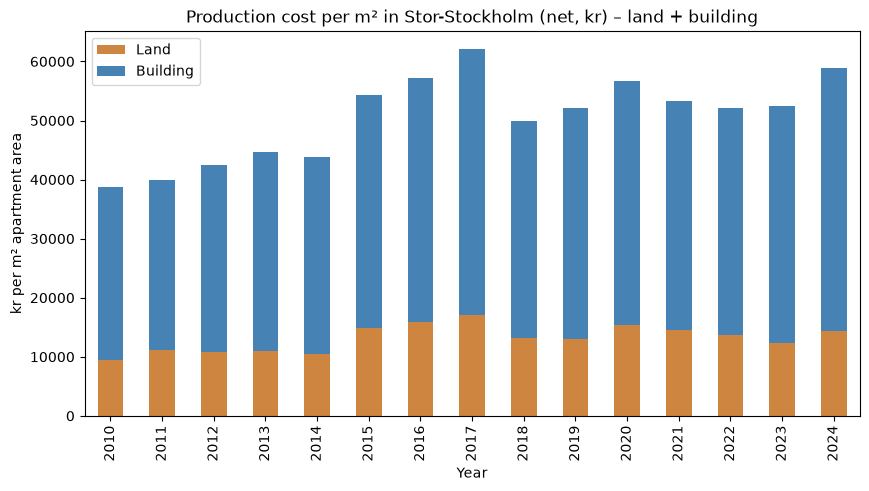

In [14]:
ax = cost.plot(kind="bar", stacked=True, figsize=(10, 5), color=["peru", "steelblue"])
ax.set_title("Production cost per m² in Stor-Stockholm (net, kr) – land + building")
ax.set_xlabel("Year")
ax.set_ylabel("kr per m² apartment area")
plt.show()

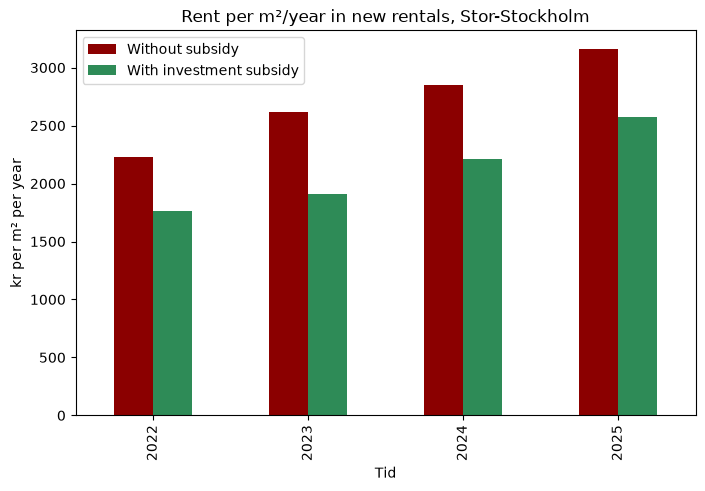

,Without subsidy,With investment subsidy,Difference
Tid,,,
2022,2233.0,1765.0,468.0
2023,2619.0,1907.0,712.0
2024,2852.0,2212.0,640.0
2025,3163.0,2574.0,589.0


In [15]:
rents = pd.read_csv("../data/raw/scb_rents_new_2022_onwards.csv")

r = rents[
    (rents["Region"] == "Stor-Stockholm")
    & (rents["AntalRum"] == "Totalt")
    & (rents["ContentsCode"] == "årshyra per kvadratmeter, kr")
    & (rents["Hyresattningsmod"].isin(["Presumtionshyra", "Presumtionshyra, inv.stöd, Hyrestak"]))
]
r = r.pivot(index="Tid", columns="Hyresattningsmod", values="value")
r.columns = ["Without subsidy", "With investment subsidy"]
r["Difference"] = r["Without subsidy"] - r["With investment subsidy"]

ax = r[["Without subsidy", "With investment subsidy"]].plot(kind="bar", figsize=(8, 5), color=["darkred", "seagreen"])
ax.set_title("Rent per m²/year in new rentals, Stor-Stockholm")
ax.set_ylabel("kr per m² per year")
plt.show()
r

In [16]:
r["Difference %"] = (r["Difference"] / r["Without subsidy"] * 100).round(0)
r

,Without subsidy,With investment subsidy,Difference,Difference %
Tid,,,,
2022,2233.0,1765.0,468.0,21.0
2023,2619.0,1907.0,712.0,27.0
2024,2852.0,2212.0,640.0,22.0
2025,3163.0,2574.0,589.0,19.0
